# 05 · What can go wrong? Stress tests and regimes

**Owner:** team lead · **Reviewed by:** _[name]_ · **Covers:** brief §8.6 (historical crisis paths plus one team-designed hypothetical), committee requirements "practical stress testing" and "resilience during market crises" (p. 4), rubric "regime-conditioned risk", decisions D2 and D5, gaps G7, G8, G14, G21
**Status:** analysis drafted with AI assistance; the owner re-runs it, checks every finding and rewrites it before sign-off (gap G12).

**The business question.** VaR describes ordinary bad days. A committee also needs to know what a **crisis** would do to the endowment, in dollars, and whether that stays inside its crisis budget (D2: at most a 25% peak-to-trough loss, applied to the worse of the historical replays and the hypothetical scenario).

**The portfolio:** today's (end-2022) minimum-variance mix at 35% equity, with 20% and 50% for comparison. Data ≤ 2022-12-31; the package is not imported until the reconciliation.

In [1]:
from pathlib import Path
import hashlib, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "raw").exists() else Path.cwd()
RAW, ART = ROOT / "data" / "raw", ROOT / "data" / "artifacts"
END = "2022-12-31"                      # test lock: nothing after this date
TICKERS = ["SPY", "EFA", "EEM", "AGG", "GLD", "XLE", "XLK"]
pd.set_option("display.width", 160, "display.precision", 4)

# chart style: validated reference palette, thin marks, recessive grid, text in ink colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.figsize": (9, 4), "figure.dpi": 110,
})

In [2]:
from scipy import optimize
from scipy import stats as st
from sklearn.covariance import LedoitWolf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox

raw = pd.read_parquet(RAW / "prices.parquet")
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] <= END]
adj = raw.pivot(index="date", columns="ticker", values="adj_close").sort_index()[TICKERS]
R = adj.pct_change(fill_method=None).iloc[1:]
EQUITY = ["SPY", "EFA", "EEM", "XLE", "XLK"]
EQ = np.array([t in EQUITY for t in TICKERS], float)
CAPS = {"SPY": .40, "EFA": .40, "EEM": .10, "XLE": .10, "XLK": .10, "GLD": .15, "AGG": .65}   # D3
NAV, D_MAX = 10_000_000, 0.25                                                                   # D2
rng = np.random.default_rng(20261028)

def min_var_at(x, S):
    res = optimize.minimize(lambda w: w @ S @ w, np.full(7, 1 / 7), method="SLSQP",
                            bounds=[(0.0, CAPS[t]) for t in TICKERS],
                            constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                         {"type": "eq", "fun": lambda w: EQ @ w - x}], options={"ftol": 1e-12})
    assert res.success, res.message
    return np.clip(res.x, 0, None) / np.clip(res.x, 0, None).sum()

S = LedoitWolf().fit(R.iloc[-756:].to_numpy()).covariance_ * 252
WEIGHTS = {x: min_var_at(x, S) for x in (0.20, 0.35, 0.50)}
w = WEIGHTS[0.35]

def fred(name):
    s = pd.read_parquet(RAW / f"fred_{name}.parquet").iloc[:, -1]
    s.index = pd.to_datetime(s.index)
    return s.loc[:END].dropna()
print("35% equity weights:", {t: f"{v:.1%}" for t, v in zip(TICKERS, w) if v > 1e-4})

35% equity weights: {'SPY': '8.2%', 'EFA': '19.4%', 'EEM': '7.4%', 'AGG': '64.1%', 'GLD': '0.9%'}


## 1 · The three required crises, replayed with today's weights

Each window runs from the S&P 500's peak close to its trough close; the path starts with the return of the day **after** the peak (gap G14). Two conventions are shown: **buy and hold** (weights drift as prices move, which is what happens if nobody trades) and **weights held at target** (rebalanced every day, as in the risk series of notebooks 03 and 06). Holding the target is the more cautious of the two in a falling equity market, so **the crisis budget D2 is checked on it**. We also report the loss in dollars, each asset's contribution, and how many trading days the portfolio took to recover its starting value afterwards.

,equity,crisis,total %,loss $,max drawdown %,"max drawdown %, weights held at target",days to recover,within D_max (25%)
0,20%,GFC 2008,-3.3,"$327,207",-16.9,-18.2,8,yes
1,20%,COVID 2020,-7.9,"$793,389",-12.0,-12.1,41,yes
2,20%,Rate shock 2022,-15.9,"$1,586,168",-16.3,-16.2,not recovered by 2022,yes
3,35%,GFC 2008,-15.6,"$1,563,525",-22.4,-24.4,148,yes
4,35%,COVID 2020,-12.3,"$1,226,066",-15.2,-15.5,71,yes
5,35%,Rate shock 2022,-18.9,"$1,888,799",-19.0,-18.8,not recovered by 2022,yes
6,50%,GFC 2008,-25.7,"$2,573,894",-28.2,-31.9,391,no
7,50%,COVID 2020,-16.9,"$1,692,445",-18.8,-19.2,82,yes
8,50%,Rate shock 2022,-20.9,"$2,091,342",-21.0,-20.9,not recovered by 2022,yes


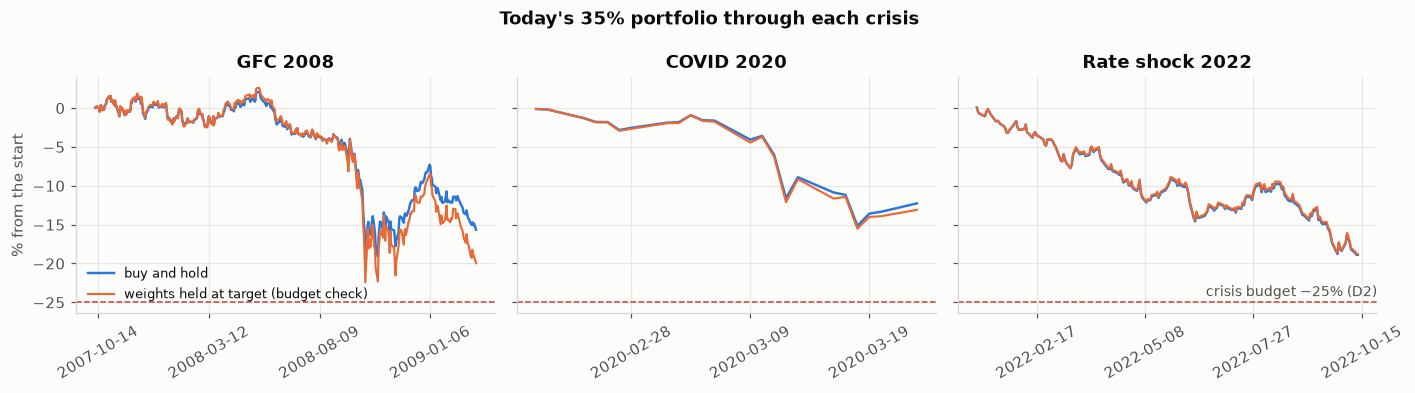

,GFC 2008,COVID 2020,Rate shock 2022
SPY,-4.52,-2.76,-2.01
EFA,-11.66,-6.31,-5.44
EEM,-4.40,-2.29,-2.16
AGG,4.74,-0.86,-9.22
GLD,0.21,-0.03,-0.06


In [3]:
CRISES = {"GFC 2008": ("2007-10-09", "2009-03-09"), "COVID 2020": ("2020-02-19", "2020-03-23"), "Rate shock 2022": ("2022-01-03", "2022-10-12")}

def replay(wx, a, b):
    seg = R.loc[(R.index > a) & (R.index <= b)]
    growth = (1 + seg).cumprod()
    path = growth @ wx
    after = R.loc[R.index > seg.index[-1]]
    later = ((1 + after).cumprod() * (wx * growth.iloc[-1].to_numpy())).sum(axis=1)
    back = later[later >= 1.0]
    recover = 0 if path.iloc[-1] >= 1 else (int(R.index.get_loc(back.index[0]) - R.index.get_loc(seg.index[-1])) if len(back) else None)
    dd = float((path / np.maximum(path.cummax(), 1.0) - 1).min())
    fixed = (1 + seg @ wx).cumprod()                                   # weights held at target every day (rebalanced)
    dd_fixed = float((fixed / np.maximum(fixed.cummax(), 1.0) - 1).min())
    return {"total %": (path.iloc[-1] - 1) * 100, "loss $": -(path.iloc[-1] - 1) * NAV, "max drawdown %": dd * 100,
            "max drawdown %, weights held at target": dd_fixed * 100,
            "days to recover": recover, "contrib": pd.Series(wx * (growth.iloc[-1].to_numpy() - 1) * 100, index=TICKERS),
            "path": path, "fixed": fixed}

rows, contribs, paths = [], {}, {}
for x, wx in WEIGHTS.items():
    for name, (a, b) in CRISES.items():
        r = replay(wx, a, b)
        rows.append({"equity": f"{x:.0%}", "crisis": name, **{k: v for k, v in r.items() if k not in ("contrib", "path", "fixed")},
                     "within D_max (25%)": "yes" if -r["max drawdown %, weights held at target"] <= D_MAX * 100 + 1e-9 else "no"})
        if x == 0.35:
            contribs[name], paths[name] = r["contrib"], (r["path"], r["fixed"])
hist = pd.DataFrame(rows)
display(hist.style.format({"total %": "{:.1f}", "loss $": "${:,.0f}", "max drawdown %": "{:.1f}",
                          "max drawdown %, weights held at target": "{:.1f}", "days to recover": "{:.0f}"}, na_rep="not recovered by 2022"))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (name, (path, fixed)) in zip(axes, paths.items()):
    ax.plot(path.index, (path - 1) * 100, color=BLUE, linewidth=1.6, label="buy and hold")
    ax.plot(fixed.index, (fixed - 1) * 100, color=ORANGE, linewidth=1.4, label="weights held at target (budget check)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))
    ax.axhline(-D_MAX * 100, color="#d03b3b", linestyle="--", linewidth=1)
    ax.set(title=name, ylabel="% from the start" if ax is axes[0] else None)
    ax.tick_params(axis="x", labelrotation=30)
axes[-1].text(1.0, -D_MAX * 100 + 0.8, "crisis budget −25% (D2)", transform=axes[-1].get_yaxis_transform(), ha="right", color=INK2, fontsize=9)
axes[0].legend(loc="lower left", fontsize=8.5)
plt.suptitle("Today's 35% portfolio through each crisis", fontweight="bold")
plt.tight_layout(); plt.show()
pd.DataFrame(contribs).round(2).loc[lambda t: t.abs().sum(axis=1) > 0.01]

**Finding:** with today's 35% weights, every required crisis stays inside the 25% budget, but the GFC comes close.
- **GFC:** worst loss 24.4% with weights held at target (22.4% buy and hold); 148 trading days to recover after the trough.
- **COVID:** 15.5%; recovered in 71 days.
- **2022:** 18.8%, **not recovered by the end of 2022**.

The 50% portfolio breaks the budget in the GFC (31.9%). In 2022 the loss came from **bonds** (AGG −9.2 points of the 18.9) as much as from equities; in the GFC AGG **gained** 4.7 points. The two crises hurt in opposite ways.
**Decision:** the 35% point passes D2 on every historical crisis, with the GFC as the binding case. The memo states the dollar figures: about USD 2.4M at the worst of a GFC, about USD 1.9M in a 2022-type rate shock.

## 2 · Regime-conditioned correlations (locked definition from notebook 01 §8)

The hypothetical scenario must use the correlations that hold **when the shock happens**, not the long-run average. Rate-hiking cycle (3-month T-bill up > 1 pp over 12 months, known at t−1), the two liquidity crises, and normal times. Weekly returns, so different closing times matter less.

In [4]:
tb = fred("DTB3").reindex(R.index, method="ffill").shift(1)
hike = (tb - tb.shift(252)) > 1.0
crisis = pd.Series(((R.index >= "2008-10-01") & (R.index <= "2008-12-31")) | ((R.index >= "2020-01-01") & (R.index <= "2020-03-31")), index=R.index)
wk = np.log1p(R).resample("W-FRI").sum()
reg_w = pd.DataFrame({"hike": hike.astype(float), "crisis": crisis.astype(float)}).resample("W-FRI").mean().reindex(wk.index) > 0.5
regime = np.where(reg_w["crisis"], "liquidity crisis", np.where(reg_w["hike"], "rate hiking", "normal"))
pairs = [("SPY", "AGG"), ("SPY", "GLD"), ("SPY", "EFA"), ("AGG", "GLD")]
tab = {}
for r_ in ["normal", "rate hiking", "liquidity crisis"]:
    sub = wk[regime == r_]
    tab[r_] = {f"{a}–{b}": sub[a].corr(sub[b]) for a, b in pairs} | {"weeks": len(sub)}
corr_tab = pd.DataFrame(tab).T
corr_tab.style.format({c: "{:+.2f}" for c in corr_tab.columns if c != "weeks"} | {"weeks": "{:.0f}"})

,SPY–AGG,SPY–GLD,SPY–EFA,AGG–GLD,weeks
normal,-0.16,+0.02,+0.87,+0.20,809
rate hiking,+0.31,+0.09,+0.84,+0.17,111
liquidity crisis,+0.68,+0.27,+0.95,+0.13,26


**Finding:** on weekly data the SPY–AGG correlation is −0.16 in normal times, **+0.31 in rate-hiking cycles** and +0.68 in the two liquidity crises (26 weeks only). Gold stays close to uncorrelated with stocks except in liquidity crises (+0.27). **International equity barely diversifies US equity in any regime** (SPY–EFA 0.84–0.95).
**Decision:** the stress scenario uses the rate-hiking correlations, and the memo does not claim EFA or EEM as a crisis hedge.

## 3 · Mapping macro shocks to the ETFs: factor betas, and do they work?

Each ETF's weekly return is regressed on weekly changes in five FRED factors: the 10-year yield (bp), oil (log change), VIX (points), the broad dollar (log change) and the Baa–Treasury credit spread (bp). Newey-West errors. We estimate the betas on all weeks and on **stress weeks** (rate-hiking or liquidity-crisis weeks), because a stress scenario should use stress sensitivities.

**Before trusting the mapping, test it:** feed it 2022's actual factor moves (3 January → 12 October) and compare the predicted loss of the 35% portfolio with what actually happened.

In [5]:
def wlast(name):
    return fred(name).resample("W-FRI").last()
fac = pd.DataFrame({"10y yield (bp)": wlast("DGS10").diff() * 100,
                    "oil (log)": np.log(wlast("DCOILWTICO").where(lambda s: s > 0)).diff(),
                    "VIX (pts)": wlast("VIXCLS").diff(),
                    "USD (log)": np.log(wlast("DTWEXBGS")).diff(),
                    "Baa spread (bp)": wlast("BAA10Y").diff() * 100}).reindex(wk.index)
data = pd.concat([wk, fac], axis=1).dropna()
stress_w = pd.Series(regime != "normal", index=wk.index).reindex(data.index)
F_COLS = list(fac.columns)

def fit_betas(mask):
    out, covs, diag = {}, {}, {}
    X = sm.add_constant(data.loc[mask, F_COLS])
    for t in TICKERS:
        m = sm.OLS(data.loc[mask, t], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
        out[t], covs[t] = m.params[F_COLS], m.cov_params().loc[F_COLS, F_COLS]
        diag[t] = {"R²": m.rsquared, "residual Ljung-Box p": acorr_ljungbox(m.resid, lags=[8])["lb_pvalue"].iloc[0]}
    return pd.DataFrame(out).T, covs, pd.DataFrame(diag).T

B_all, C_all, D_all = fit_betas(pd.Series(True, index=data.index))
B_str, C_str, D_str = fit_betas(stress_w)
print(f"weeks: all {len(data)}, stress {int(stress_w.sum())}")
display(pd.concat({"all weeks": D_all, "stress weeks": D_str}, axis=1).round(3))
display(pd.concat({"all weeks": B_all, "stress weeks": B_str}, axis=1).round(4))

# validation: predict 2022 from its actual cumulative factor moves
f22 = data.loc["2022-01-07":"2022-10-14", F_COLS].sum()
actual = float(np.prod(1 + (R.loc[(R.index > "2022-01-03") & (R.index <= "2022-10-12")] @ w)) - 1)
pred_all, pred_str = (float(np.expm1(w @ (B @ f22).to_numpy())) for B in (B_all, B_str))   # betas act on log returns
pd.DataFrame({"2022 factor moves": f22.round(3)}).T.join(pd.DataFrame(
    {"actual 35% loss %": [actual * 100], "predicted, all-week betas %": [pred_all * 100],
     "predicted, stress betas %": [pred_str * 100]}, index=["2022 factor moves"])).round(2)

weeks: all 886, stress 130


all weeks                      stress weeks                     
           R² residual Ljung-Box p           R² residual Ljung-Box p
SPY     0.698                0.000        0.784                0.008
EFA     0.760                0.001        0.865                0.417
EEM     0.682                0.000        0.773                0.106
AGG     0.600                0.000        0.544                0.001
GLD     0.277                0.074        0.317                0.310
XLE     0.605                0.063        0.746                0.049
XLK     0.576                0.014        0.638                0.081

all weeks                                                 stress weeks                                              
    10y yield (bp) oil (log) VIX (pts) USD (log) Baa spread (bp) 10y yield (bp) oil (log) VIX (pts) USD (log) Baa spread (bp)
SPY         0.0002   -0.0122   -0.0046   -0.8576         -0.0003        -0.0001    0.0370   -0.0056   -0.8201         -0.0002
EFA         0.0003   -0.0209   -0.0039   -1.7638         -0.0003         0.0000    0.0154   -0.0044   -1.8702         -0.0001
EEM         0.0004   -0.0086   -0.0044   -2.0904         -0.0002         0.0006   -0.0091   -0.0047   -2.5389          0.0000
AGG        -0.0005   -0.0035   -0.0004   -0.1764         -0.0001        -0.0005    0.0024   -0.0008   -0.3349         -0.0000
GLD        -0.0003    0.0505    0.0009   -1.5013          0.0002        -0.0003    0.0659    0.0013   -1.3982         -0.0001
XLE         0.0004    0.2291   -0.0038   -1.3512         -0.0003        -0.0002    0.3156   -0.0052   -1.1848         -0.0002
XLK         0.0001   -0.0260   -0.0049   -0.6743         -0.0003         0.0000   -0.0012   -0.0053   -0.8693         -0.0002

,10y yield (bp),oil (log),VIX (pts),USD (log),Baa spread (bp),actual 35% loss %,"predicted, all-week betas %","predicted, stress betas %"
2022 factor moves,248.0,0.13,14.8,0.11,43.0,-18.77,-15.07,-17.8


**Finding:**
- **The factor mapping passes its test.** Fed 2022's actual factor moves (10-year yield +248 bp, oil +13%, VIX +15, dollar +11%, Baa +43 bp), the **stress betas** predict a 17.8% loss against the actual 18.8%; all-week betas predict only 15.1%. Stress sensitivities are the right ones for a stress scenario.
- Fit is good for the equity ETFs and AGG (R² 0.54–0.87 on stress weeks) and weak for gold (0.32). Residuals are autocorrelated for some ETFs on all weeks, so Newey-West errors are used throughout.

## 4 · The team's hypothetical: a stagflation and correlation-breakdown episode (D5)

Designed by the team, not drawn from history. Over an episode of about three quarters, measured peak to trough (D5): oil +40%, the 10-year yield +150 bp as the central bank keeps hiking, the VIX up 25 points, the dollar +8%, the Baa spread +150 bp. The shock sizes are the team's initial assumptions in `config.yaml` (2022 saw about +240 bp in the 10-year yield). ETF moves come from the **stress betas**, and a band shows how uncertain the betas are (2,000 draws of the betas from their estimated distributions).

**Liquidity overlay (gap G7):** AGG can trade several percent below the value of its bonds in a panic (−6.8% on 10 October 2008). We add one such day (AGG −5%) at the trough.

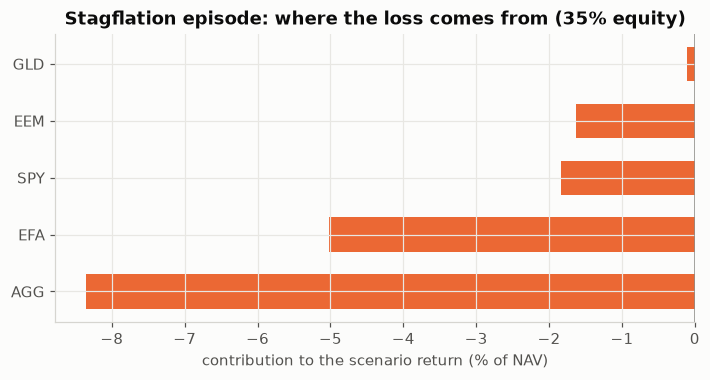

,"loss, all-week betas %","loss, stress betas %",90% band %,with a liquidity day %,loss $ (stress betas + liquidity day),within D_max (25%)
equity,,,,,,
20%,12.9,14.0,10.8 to 17.1,17.2,"$1,720,810",yes
35%,14.7,15.6,12.4 to 19.0,18.8,"$1,880,513",yes
50%,16.2,17.1,13.3 to 20.5,19.6,"$1,956,160",yes


,as designed (config),2022-size rates,severe: rates + credit + panic
20% equity,17.2,20.3,23.4
35% equity,18.8,21.2,25.5
50% equity,19.6,21.2,26.4


In [6]:
SHOCK = pd.Series({"10y yield (bp)": 150, "oil (log)": np.log(1.40), "VIX (pts)": 25, "USD (log)": np.log(1.08), "Baa spread (bp)": 150})
def scenario(wx, B, C, shock=SHOCK, draws=2000):
    central = float(np.expm1(wx @ (B @ shock).to_numpy()))          # log-return mapping, reported as a simple return
    sims = np.zeros(draws)
    for i, t in enumerate(TICKERS):
        b = rng.multivariate_normal(B.loc[t].to_numpy(), C[t].to_numpy(), size=draws)
        sims += wx[i] * (b @ shock.to_numpy())
    return central, np.quantile(np.expm1(sims), [0.05, 0.95])

rows = []
for x, wx in WEIGHTS.items():
    c_all, _ = scenario(wx, B_all, C_all)
    c, band = scenario(wx, B_str, C_str)
    liq = c - wx[TICKERS.index("AGG")] * 0.05
    rows.append({"equity": f"{x:.0%}", "loss, all-week betas %": -c_all * 100, "loss, stress betas %": -c * 100,
                 "90% band %": f"{-band[1] * 100:.1f} to {-band[0] * 100:.1f}", "with a liquidity day %": -liq * 100,
                 "loss $ (stress betas + liquidity day)": -liq * NAV,
                 "within D_max (25%)": "yes" if -liq <= D_MAX else "no"})
hyp = pd.DataFrame(rows).set_index("equity")
LADDER = {"as designed (config)": SHOCK,
          "2022-size rates": pd.Series({**SHOCK, "10y yield (bp)": 250}),
          "severe: rates + credit + panic": pd.Series({**SHOCK, "10y yield (bp)": 250, "Baa spread (bp)": 250, "VIX (pts)": 40,
                                                      "oil (log)": np.log(1.60), "USD (log)": np.log(1.10)})}
ladder = pd.DataFrame({name: {f"{x:.0%} equity": -(scenario(wx, B_str, C_str, sh, draws=200)[0] - wx[TICKERS.index("AGG")] * 0.05) * 100
                              for x, wx in WEIGHTS.items()} for name, sh in LADDER.items()})
contrib_h = pd.Series(w * (B_str @ SHOCK).to_numpy() * 100, index=TICKERS)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
c = contrib_h[contrib_h.abs() > 0.01].sort_values()
ax.barh(c.index, c.values, color=[ORANGE if v < 0 else AQUA for v in c.values], height=0.6)
ax.axvline(0, color=GREY, linewidth=1)
ax.set(xlabel="contribution to the scenario return (% of NAV)", title="Stagflation episode: where the loss comes from (35% equity)")
plt.show()
display(hyp.style.format({"loss, all-week betas %": "{:.1f}", "loss, stress betas %": "{:.1f}", "with a liquidity day %": "{:.1f}",
                          "loss $ (stress betas + liquidity day)": "${:,.0f}"}))
ladder.style.format("{:.1f}").set_caption("Severity ladder: episode loss % with stress betas and a liquidity day (budget 25%)")

**Finding:**
- **The team's scenario (as designed) costs the 35% portfolio 15.6%, or 18.8% with a liquidity day** (about USD 1.9M), within the budget. The beta-uncertainty band is 12.4–19.0%.
- **The biggest single source of loss is AGG** (−8.4 points), ahead of EFA (−5.0): in stagflation the "safe" sleeve is the problem, as in 2022.
- **The scenario as designed is milder than 2022 on rates** (+150 bp vs +248 bp). With 2022-size rates the loss is 21.2%. In the severe version (2022 rates, a 250 bp credit shock, VIX +40, oil +60%), **the 35% portfolio loses 25.5% and just breaks the budget**.
- At 2022-size rates, the 20% portfolio loses almost as much as the 35% one (20.3% vs 21.2%): **less equity does not protect against a rate shock**.

**Decision:** recalibrate the hypothetical before the freeze so it is at least as severe as 2022 on rates; the "2022-size rates" row is the proposed central case (D5 sizes), with the severe row as the committee's "what breaks us" sensitivity.

## 5 · Reverse stress test: what would it take to breach the 25% budget?

Instead of asking what a chosen shock does, ask which shock is **most plausible** among all those that would cost exactly 25% over an episode. Plausibility is measured by the Mahalanobis distance of the factor move, using the stress-week factor covariance scaled to a three-quarter (39-week) episode. Under a linear-normal model, the chance that a stress episode crosses the 25% boundary is the one-sided normal tail beyond that distance; the closed-form answer is f* = ln(0.75) · Σ b / (b′ Σ b), where b is the portfolio's stress-beta exposure to each factor.

In [7]:
Sigma_f = data.loc[stress_w, F_COLS].cov().to_numpy() * 39
rows = []
for x, wx in WEIGHTS.items():
    b = (B_str.T.to_numpy() @ wx)
    f_star = np.log(1 - D_MAX) * Sigma_f @ b / (b @ Sigma_f @ b)     # a 25% simple loss = log return ln(0.75)
    dist = float(np.sqrt(f_star @ np.linalg.solve(Sigma_f, f_star)))
    rows.append({"equity": f"{x:.0%}", **dict(zip(F_COLS, f_star)), "how many standard deviations": dist,
                 "chance per stress episode (linear-normal model)": float(st.norm.sf(dist))})
rev = pd.DataFrame(rows).set_index("equity")
rev.style.format({"10y yield (bp)": "{:+.0f}", "oil (log)": "{:+.2f}", "VIX (pts)": "{:+.1f}", "USD (log)": "{:+.3f}",
                  "Baa spread (bp)": "{:+.0f}", "how many standard deviations": "{:.1f}", "chance per stress episode (linear-normal model)": "{:.1%}"})

,10y yield (bp),oil (log),VIX (pts),USD (log),Baa spread (bp),how many standard deviations,chance per stress episode (linear-normal model)
equity,,,,,,,
20%,+94,-0.70,+72.9,+0.183,+140,2.9,0.2%
35%,+50,-0.57,+64.5,+0.144,+116,2.3,1.1%
50%,+24,-0.49,+53.8,+0.117,+97,1.9,3.1%


**Finding:** the most plausible way for the 35% portfolio to lose 25% over a stress episode is **not** stagflation but a **deflationary crash**: VIX +65 points, oil −43%, the Baa spread +116 bp and the dollar +14%, with yields barely moving. That is a GFC-type event about 2.3 standard deviations away: roughly a **1% chance per stress episode** under a linear-normal model (0.2% for 20% equity, 3% for 50%). The probability is rough (fat tails make it an under-estimate); the **direction** is the robust finding.
**Decision:** the memo names both threats: a deflationary crash (the most likely route to a budget breach, where AGG helps) and stagflation (the scenario where AGG hurts). The portfolio is built to survive both within 25%.

## 6 · Two recent episodes, pre-registered now and computed only after the freeze (gap G21)

These windows are fixed **today**, before anyone looks at 2023–2026 data, and replayed once after the methodology freeze (30 October 2026) with the same code as §1. The dates come from news reports and are not adjusted afterwards.

| Episode | Window (peak close → trough close, S&P 500) | Why it matters for this portfolio |
|---|---|---|
| 2025 US tariff shock | 2025-02-19 → 2025-04-08 | Stocks, long Treasuries and the dollar fell together ("sell America"): the hedge failure of notebook 01 §8 |
| 2026 Iran war / Strait of Hormuz | 2026-02-27 → 2026-03-30 | An oil supply shock with yields up and gold falling: close to our stagflation scenario |

In [8]:
PREREGISTERED = {"2025 tariff shock": ("2025-02-19", "2025-04-08"), "2026 Hormuz shock": ("2026-02-27", "2026-03-30")}
print("pre-registered windows (not computed before the freeze):", PREREGISTERED)

pre-registered windows (not computed before the freeze): {'2025 tariff shock': ('2025-02-19', '2025-04-08'), '2026 Hormuz shock': ('2026-02-27', '2026-03-30')}


## 7 · Reconciliation with the pipeline

The pipeline's stress matrix replays its own focus portfolio (Min CVaR). With those weights our replay must match.

In [9]:
status = json.loads((ART / "status.json").read_text())
wp = np.array([status["weights"][t] for t in TICKERS])
sm_ = pd.read_parquet(ART / "stress_matrix.parquet")
PIPE_NAME = {"GFC 2008": "GFC 2008", "COVID 2020": "COVID crash 2020", "Rate shock 2022": "Rate shock 2022"}
pd.DataFrame({name: {"ours %": replay(wp, a, b)["total %"], "pipeline %": float(sm_.loc["Min CVaR", PIPE_NAME[name]]) * 100}
              for name, (a, b) in CRISES.items()}).T.round(3)

,ours %,pipeline %
GFC 2008,1.077,1.077
COVID 2020,-6.603,-6.603
Rate shock 2022,-14.650,-14.650


**Finding:** with the pipeline's weights our replay matches its stress matrix exactly (GFC +1.08%, COVID −6.60%, 2022 −14.65%), after the Phase 0 window fix.

## Evidence table and what it means for the endowment

| Claim | Evidence | Status |
|---|---|---|
| The 35% point survives every required crisis within the 25% budget | §1: GFC 24.4%, COVID 15.5%, 2022 18.8% (weights held at target) | **Strong** (the GFC is close) |
| The SPY–AGG hedge flips in rate-hiking cycles | §2: −0.16 normal, +0.31 hiking (weekly); notebook 01 §8 tests | **Moderate** (H1) |
| The factor mapping is reliable for stress | §3: 2022 predicted 17.8% vs actual 18.8% with stress betas | **Strong** (one validation episode) |
| The team's stagflation scenario stays within budget | §4: 18.8% as designed; 21.2% at 2022-size rates; 25.5% severe | **Within budget except the severe case** |
| The most likely budget breach is a deflationary crash | §5: 2.3 standard deviations, about 1% per stress episode | **Direction strong, probability rough** |

**What this means for the endowment (input to the memo), at 35% equity on USD 10M:**
1. A GFC repeat would cost about **USD 2.4M at the worst point** and take about 7 months to recover; a 2022 repeat about **USD 1.9M**, and bonds would be half the problem.
2. Two different crises threaten the fund: a **deflationary crash** (bonds help) and **stagflation** (bonds hurt). The portfolio stays within the 25% budget in both at historical severity; only a combined severe stagflation breaks it.
3. Holding less equity does **not** protect against a rate shock; the crisis budget, not a lower equity share, is the protection there.